# P5b · AVD: análise exploratória do recorte Elliptic++

Dados: `data/dataset_parte2/` (14.182 carteiras, 25.111 arestas).
Pergunta de pesquisa: *Carteiras ilícitas participam mais de ciclos de repasse (ciclos negativos) do que as lícitas?*

Etapas: 1. carga · 2. estrutural · 3. distribucional · 4. faltantes · 5. relacional · 6. outliers · 7. gráficos exploratórios · 8. gráficos explanatórios · 9. da exploração à explicação.

> Regra do projeto: a **escolha do tipo de gráfico** e a **interpretação** são do Vagner (não da IA).
> Células de código escritas com apoio de IA estão marcadas com `# [IA]`. Textos em markdown são do Vagner, salvo indicação na própria célula; revisões de texto feitas com IA estão no `docs/REGISTRO_IA.md`.

## 1. Carga dos dados

In [1]:
# [IA] Claude Code – importação e definiçção de variáveis
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PASTA = "../../data/dataset_parte2/"
SAIDA = "../../out/parte2/avd/"
os.makedirs(SAIDA, exist_ok=True)

nos = pd.read_csv(PASTA + "nos.csv")
arestas = pd.read_csv(PASTA + "arestas.csv")

print("nós:", nos.shape, "| arestas:", arestas.shape)
nos.head()

nós: (14182, 9) | arestas: (25111, 6)


,endereco,btc_received_total,btc_sent_total,total_txs,fees_total,lifetime_in_blocks,num_timesteps_appeared_in,saldo_btc,classe
0,111iu559diy1cBDTP9cRhy8sYYcECvvrw,0.028167,0.028167,2.0,0.000708,1.0,1.0,0.000000,ilicito
1,111khWGs3Mj7UgKT7aS6hLsYK11ii4Gmw,207.237033,240.848000,5.0,0.048075,40324.0,2.0,-33.610967,licito
2,1121LXUU8xwRaNqpBJDPjyRL1ctApsS4uU,0.006800,0.006800,2.0,0.046897,3.0,1.0,0.000000,ilicito
3,11238JxaWpG9UsmVapWF4kNkhH9hZhxYeh,3.136576,3.659237,6.0,0.008615,4.0,1.0,-0.522661,desconhecido
4,112GBCxMnbDkZdSSKVehkQ5F9YJQ9V8yA,0.005100,0.005100,2.0,0.004992,7.0,1.0,0.000000,desconhecido


In [2]:
# [IA] Claude Code – tipos das colunas
nos.dtypes

endereco                         str
btc_received_total           float64
btc_sent_total               float64
total_txs                    float64
fees_total                   float64
lifetime_in_blocks           float64
num_timesteps_appeared_in    float64
saldo_btc                    float64
classe                           str
dtype: object

In [3]:
# [IA] Claude Code – primeiras arestas
arestas.head()

,origem,destino,peso,valor_btc,n_txs,valor_faltante
0,1121LXUU8xwRaNqpBJDPjyRL1ctApsS4uU,3JUgPFWr3kMLrm1cauMcgcEMm6RZtLWnnM,6.306893,6.306893,1,False
1,11238JxaWpG9UsmVapWF4kNkhH9hZhxYeh,124wEpEZZG4ZyDEYDchC9vGZjrGyoVUmi8,0.000000,8.718053,1,False
2,11238JxaWpG9UsmVapWF4kNkhH9hZhxYeh,195eqvV43dFxexf4cqEWzmCgNXNiyeecmS,0.000000,24.009933,1,False
3,11238JxaWpG9UsmVapWF4kNkhH9hZhxYeh,1Bg9bJSvzpwdBTTP2QK2qjwpYrkvzeCiqv,0.000000,24.009933,1,False
4,11238JxaWpG9UsmVapWF4kNkhH9hZhxYeh,1F3mTdpMFvs8WhKgJtFhXgdL83TkTPBEWc,0.000000,8.718053,1,False


## 2. Estrutural

In [4]:
print("Nós:", len(nos))
print("Arestas:", len(arestas))
print("Arestas com peso < 0:", (arestas["peso"] < 0).sum())
print("Arestas com peso = 0:", (arestas["peso"] == 0).sum())
# [IA] Claude Code – densidade dirigida = |E| / (|V| (|V| − 1))
print("Densidade:", len(arestas) / (len(nos) * (len(nos) - 1)))
nos["classe"].value_counts()

Nós: 14182
Arestas: 25111
Arestas com peso < 0: 3279
Arestas com peso = 0: 8658
Densidade: 0.00012485894757635662


classe
ilicito         5208
desconhecido    4713
licito          4261
Name: count, dtype: int64

In [5]:
# [IA] Claude Code – graus de entrada e saída contados com pandas (não usa graph.py)
grau_saida = arestas.groupby("origem").size()
grau_entrada = arestas.groupby("destino").size()

nos["grau_saida"] = nos["endereco"].map(grau_saida).fillna(0).astype(int)
nos["grau_entrada"] = nos["endereco"].map(grau_entrada).fillna(0).astype(int)

nos[["grau_entrada", "grau_saida"]].describe()

,grau_entrada,grau_saida
count,14182.000000,14182.000000
mean,1.770625,1.770625
std,30.511869,9.672418
min,0.000000,0.000000
25%,0.000000,1.000000
50%,0.000000,1.000000
75%,1.000000,1.000000
max,2719.000000,1002.000000


In [6]:
# [IA] Claude Code – três níveis do dado: transações, arestas e carteiras (contagens do recorte)
transacoes_rec = pd.read_csv(PASTA + "transacoes_recorte.csv")

niveis = pd.DataFrame({
    "nível": ["transação", "aresta (carteira → carteira)", "carteira"],
    "quantidade": [len(transacoes_rec), len(arestas), len(nos)],
    "origem da classe": [
        "rótulo do Elliptic++ (txs_classes.csv)",
        "herda a classe da transação que a formou",
        "regra do Elliptic++ sobre as transações da carteira",
    ],
})
print(niveis.to_string(index=False))
print()
print("Arestas por transação (média):", round(len(arestas) / len(transacoes_rec), 1))
print("Arestas que juntam mais de uma transação (n_txs > 1):", (arestas["n_txs"] > 1).sum())
print("Transações por classe:")
print(transacoes_rec["classe"].value_counts().reindex(["ilicito", "desconhecido", "licito"]))

                       nível  quantidade                                    origem da classe
                   transação        2555              rótulo do Elliptic++ (txs_classes.csv)
aresta (carteira → carteira)       25111            herda a classe da transação que a formou
                    carteira       14182 regra do Elliptic++ sobre as transações da carteira

Arestas por transação (média): 9.8
Arestas que juntam mais de uma transação (n_txs > 1): 239
Transações por classe:
classe
ilicito          644
desconhecido    1130
licito           781
Name: count, dtype: int64


In [7]:
# [IA] Claude Code – combinações de classes dentro de cada aresta: prova de que nenhuma aresta mistura classes
from itertools import combinations

arestas_classes = pd.read_csv(PASTA + "arestas_transacoes.csv")
CLASSES_TX = ["ilicito", "licito", "desconhecido"]

# todas as 7 combinações possíveis: 3 puras, 3 em dupla e 1 com as três classes
todas = [c for k in (1, 2, 3) for c in combinations(CLASSES_TX, k)]

def combinacao(linha):
    """Classes das transações que formam a aresta, ex.: ('ilicito', 'desconhecido')."""
    return tuple(c for c in CLASSES_TX if linha[f"n_tx_{c}"] > 0)

arestas_classes["combinacao"] = arestas_classes.apply(combinacao, axis=1)
varias_tx = arestas_classes["n_txs"] > 1

tabela = pd.DataFrame({
    "combinação": [" + ".join(c) for c in todas],
    "todas as arestas": [(arestas_classes["combinacao"] == c).sum() for c in todas],
    "arestas com n_txs > 1": [((arestas_classes["combinacao"] == c) & varias_tx).sum() for c in todas],
})
print(tabela.to_string(index=False))
print()
print("Total conferido:", tabela["todas as arestas"].sum(), "de", len(arestas_classes), "arestas")
mistas = tabela.loc[tabela["combinação"].str.contains(r"\+"), "todas as arestas"].sum()
print("Arestas com mais de uma classe:", mistas)
assert mistas == 0

                     combinação  todas as arestas  arestas com n_txs > 1
                        ilicito              5207                     21
                         licito             15126                    205
                   desconhecido              4778                     13
               ilicito + licito                 0                      0
         ilicito + desconhecido                 0                      0
          licito + desconhecido                 0                      0
ilicito + licito + desconhecido                 0                      0

Total conferido: 25111 de 25111 arestas
Arestas com mais de uma classe: 0


In [8]:
# [IA] Claude Code – rótulo das transações nas arestas (gerado por scripts/rotular_transacoes.py): quantas são desconhecidas
arestas_tx = pd.read_csv(PASTA + "arestas_transacoes.csv")
transacoes = pd.read_csv(PASTA + "transacoes_recorte.csv")
ORDEM_TX = ["ilicito", "desconhecido", "licito"]

n = len(arestas_tx)
print(f"Arestas do recorte: {n}")
for c in ORDEM_TX:
    alguma = (arestas_tx[f"n_tx_{c}"] > 0).sum()
    print(f"  com pelo menos 1 transação {c}: {alguma} ({100 * alguma / n:.1f}%)")
so_desc = (arestas_tx["n_tx_desconhecido"] == arestas_tx["n_txs"]).sum()
print(f"  só com transações desconhecidas: {so_desc} ({100 * so_desc / n:.1f}%)")

print()
print(f"Transações distintas que formam o recorte: {len(transacoes)}")
for c in ORDEM_TX:
    k = (transacoes["classe"] == c).sum()
    print(f"  {c}: {k} ({100 * k / len(transacoes):.1f}%)")
print(f"Arestas por transação (média): {n / len(transacoes):.1f}")

# cada aresta tem transações de uma classe só, então a aresta recebe essa classe
CLASSES_TX = [f"n_tx_{c}" for c in ORDEM_TX]
assert ((arestas_tx[CLASSES_TX] > 0).sum(axis=1) == 1).all()
arestas_tx["classe_tx"] = arestas_tx[CLASSES_TX].idxmax(axis=1).str.replace("n_tx_", "")
arestas = arestas.merge(arestas_tx[["origem", "destino", "classe_tx"]], on=["origem", "destino"], how="left")

Arestas do recorte: 25111
  com pelo menos 1 transação ilicito: 5207 (20.7%)
  com pelo menos 1 transação desconhecido: 4778 (19.0%)
  com pelo menos 1 transação licito: 15126 (60.2%)
  só com transações desconhecidas: 4778 (19.0%)

Transações distintas que formam o recorte: 2555
  ilicito: 644 (25.2%)
  desconhecido: 1130 (44.2%)
  licito: 781 (30.6%)
Arestas por transação (média): 9.8


É importante enfatizar que nós juntamos previamente os pares ordenados em apenas uma aresta. Logo, se houver 10 ligações A → B, elas viram apenas 1 aresta no nosso recorte, e a variável n_txs guarda o número de transações desse par ordenado.

Conseguimos observar que possuímos mais arestas com peso positivo (13.174, 52,5%), mas ainda possuímos muitas arestas com peso nulo e negativo (8.658, 34,5%, e 3.279, 13,1%, respectivamente). O peso neste projeto funciona da seguinte forma: o peso de uma aresta A → B é o saldo líquido da carteira de destino B, ou seja, o total de BTC recebido menos o total enviado. Peso positivo indica que B acumula BTC, negativo indica que B repassa mais do que recebe, e nulo indica que B envia tudo o que recebe.

Em relação à classe das carteiras (ilícito, lícito e desconhecido), temos valores parecidos entre os grupos: 5.208 ilícitas (36,7%), 4.713 desconhecidas (33,2%) e 4.261 lícitas (30,0%).

Além disso, os graus de entrada e de saída têm a mesma média (1,77), o que é esperado, pois cada aresta soma 1 na saída de uma carteira e 1 na entrada de outra. Porém, há uma diferença grande no desvio padrão entre eles (30,51 no grau de entrada contra 9,67 no grau de saída): poucas carteiras recebem de muitas outras (o maior grau de entrada é 2.719, contra 1.002 no de saída).

A densidade do grafo é próxima de 0, então é um grafo esparso: cada carteira se liga a poucas das outras carteiras do recorte.

O grafo é formado por 2.555 transações. Uma transação pode gerar várias arestas, e uma aresta pode juntar várias transações do mesmo par. Por isso, a forma que escolhemos de juntar as ligações em uma aresta poderia fazer uma mesma aresta reunir uma transação lícita e outra ilícita. Mas em nenhum caso do recorte isso ocorre. Das 2.555 transações, 1.130 são desconhecidas, 644 são ilícitas e 781 são lícitas.

## 3. Distribucional

In [9]:
# [IA] Claude Code – lista dos atributos numéricos das carteiras
ATRIBUTOS = nos.select_dtypes("number").columns.tolist()
ATRIBUTOS

['btc_received_total',
 'btc_sent_total',
 'total_txs',
 'fees_total',
 'lifetime_in_blocks',
 'num_timesteps_appeared_in',
 'saldo_btc',
 'grau_saida',
 'grau_entrada']

In [10]:
# [IA] Claude Code – estatísticas de cada atributo das carteiras
nos[ATRIBUTOS].describe().T

,count,mean,std,min,25%,50%,75%,max
btc_received_total,14182.0,2.016689,70.304372,0.000000,0.000000,0.003792,0.016198,6610.127256
btc_sent_total,14182.0,2.974309,167.395212,0.000000,0.002000,0.005100,0.024080,19195.848900
total_txs,14182.0,2.092512,8.891691,1.000000,1.000000,2.000000,2.000000,639.000000
fees_total,14182.0,0.030692,0.060530,0.000000,0.002468,0.004892,0.039292,2.108203
lifetime_in_blocks,14182.0,1362.787830,7336.365419,0.000000,0.000000,1.000000,3.000000,96767.000000
num_timesteps_appeared_in,14182.0,1.119306,0.796479,1.000000,1.000000,1.000000,1.000000,39.000000
saldo_btc,14182.0,-0.957620,107.557803,-12585.721644,-0.004737,0.000000,0.000000,1078.828715
grau_saida,14182.0,1.770625,9.672418,0.000000,1.000000,1.000000,1.000000,1002.000000
grau_entrada,14182.0,1.770625,30.511869,0.000000,0.000000,0.000000,1.000000,2719.000000


In [11]:
# [IA] Claude Code – estatísticas dos atributos das arestas
arestas[["peso", "valor_btc", "n_txs"]].describe().T

,count,mean,std,min,25%,50%,75%,max
peso,25111.0,-50.369053,547.880705,-12585.721644,0.000000,0.003737,2.054115,1078.828715
valor_btc,25111.0,46.093009,176.194548,0.000250,1.434474,4.000000,12.676157,6838.178522
n_txs,25111.0,1.014974,0.226515,1.000000,1.000000,1.000000,1.000000,22.000000


In [12]:
# [IA] Claude Code – cálculo dos números citados na nota da seção 3
print("Carteiras com saldo exatamente zero (%):", round(100 * (nos["saldo_btc"] == 0).mean(), 1))
print("Menor e maior saldo (BTC):", round(nos["saldo_btc"].min(), 2), round(nos["saldo_btc"].max(), 2))

muito_negativas = arestas[arestas["peso"] < -100]
print("Arestas com peso < -100:", len(muito_negativas))
print("Carteiras de destino dessas arestas:", muito_negativas["destino"].nunique())
print("Soma do peso dessas arestas:", round(muito_negativas["peso"].sum(), 2))
print("Soma do peso das demais arestas:", round(arestas.loc[arestas["peso"] >= -100, "peso"].sum(), 2))

print("Pares com n_txs = 1 (%):", round(100 * (arestas["n_txs"] == 1).mean(), 1))

Carteiras com saldo exatamente zero (%): 52.4
Menor e maior saldo (BTC): -12585.72 1078.83
Arestas com peso < -100: 754
Carteiras de destino dessas arestas: 4
Soma do peso dessas arestas: -1642368.73
Soma do peso das demais arestas: 377551.44
Pares com n_txs = 1 (%): 99.0


Na maioria dos atributos, os valores ficam concentrados nos números pequenos, mas algumas carteiras apresentam valores muito altos. Por isso, a média acaba ficando bem maior que a mediana, e o desvio padrão também costuma ser alto. O BTC recebido tem mediana de 0,0038 e média de 2,02. No BTC enviado, a mediana é 0,0051 e a média é 2,97, chegando ao máximo de 19.196 BTC. O número de transações tem mediana 2 e máximo de 639. Em geral, uma carteira movimenta pouco BTC, enquanto poucas carteiras muito grandes concentram a maior parte do volume.

O saldo funciona de um jeito um pouco diferente. Mais da metade das carteiras (52,4%) tem saldo exatamente zero. Mesmo assim, existem alguns saldos negativos muito altos: os valores vão de −12.586 a
+1.079 BTC. Por causa desses valores extremos, a média (−0,96) fica abaixo da mediana (0). Lembrando que isso é um recorte e não todo a história do Bitcoin, por isso, podemos ter valores negativos

Nas ligações entre as carteiras, o peso tem média de −50,37 e mediana de 0,0037. A média fica negativa por causa de poucos casos muito extremos: as 754 ligações com peso abaixo de −100 pertencem a apenas 4 carteiras e, juntas, têm um peso maior que o total das outras ligações. Isso acontece porque o saldo da carteira de destino é repetido em todas as ligações que chegam até ela. O valor_btc tem mediana 4 e média 46,1. O n_txs é quase sempre 1: isso acontece em 99% dos pares, com média de 1,01 e máximo de 22. Portanto, cada par de carteiras normalmente faz uma única transação. O num_timesteps_appeared_in também tem mediana 1, o que significa que a maioria das carteiras aparece em apenas um intervalo de tempo.

Em resumo, a média sozinha pode dar uma impressão errada sobre esses dados, porque poucos valores muito altos ou muito baixos influenciam bastante o resultado. Por isso, nos gráficos usamos principalmente medianas e proporções.

## 4. Dados faltantes

In [13]:
# [IA] Claude Code – nulos por coluna
print("Nulos em nos.csv:")
print(nos.isna().sum())
print()
print("Nulos em arestas.csv:")
print(arestas.isna().sum())

Nulos em nos.csv:
endereco                     0
btc_received_total           0
btc_sent_total               0
total_txs                    0
fees_total                   0
lifetime_in_blocks           0
num_timesteps_appeared_in    0
saldo_btc                    0
classe                       0
grau_saida                   0
grau_entrada                 0
dtype: int64

Nulos em arestas.csv:
origem            0
destino           0
peso              0
valor_btc         0
n_txs             0
valor_faltante    0
classe_tx         0
dtype: int64


### 4.1 Transações sem rótulo (arestas)

In [14]:
# [IA] Claude Code – atributos das arestas por classe da transação (mediana e média)
colunas_aresta = ["valor_btc", "peso", "n_txs"]
print("Medianas:")
print(arestas.groupby("classe_tx")[colunas_aresta].median().reindex(ORDEM_TX).round(4))
print()
print("Médias:")
print(arestas.groupby("classe_tx")[colunas_aresta].mean().reindex(ORDEM_TX).round(2))

Medianas:
              valor_btc  peso  n_txs
classe_tx                           
ilicito          2.6135  0.85    1.0
desconhecido     1.2467  0.00    1.0
licito           6.1871  0.01    1.0

Médias:
              valor_btc   peso  n_txs
classe_tx                            
ilicito            3.26   1.98   1.01
desconhecido       8.00  13.64   1.00
licito            72.87 -88.61   1.02


In [15]:
# [IA] Claude Code – compara as classes de transação (ilícita, lícita, desconhecida) e rotulada x desconhecida
classe_carteira = nos.set_index("endereco")["classe"]
comp = arestas[["origem", "destino", "valor_btc", "peso", "classe_tx"]].copy()
comp["rotulo_tx"] = comp["classe_tx"].eq("desconhecido").map({True: "desconhecida", False: "rotulada"})
comp["classe_origem"] = comp["origem"].map(classe_carteira)
comp["classe_destino"] = comp["destino"].map(classe_carteira)
transacoes["rotulo_tx"] = transacoes["classe"].eq("desconhecido").map({True: "desconhecida", False: "rotulada"})

print("1) Arestas geradas por transação (n_arestas)")
print(transacoes.groupby("classe")["n_arestas"].describe()[["count", "mean", "50%", "max"]].reindex(ORDEM_TX).round(1))
print(transacoes.groupby("rotulo_tx")["n_arestas"].describe()[["count", "mean", "50%", "max"]].round(1))
print()
print("2) Atributos das arestas: rotulada x desconhecida")
print("Medianas:")
print(comp.groupby("rotulo_tx")[["valor_btc", "peso"]].median().round(4))
print("Médias:")
print(comp.groupby("rotulo_tx")[["valor_btc", "peso"]].mean().round(2))
print()
print("3) Classe da carteira de ORIGEM por classe da transação (% por linha)")
print((100 * pd.crosstab(comp["classe_tx"], comp["classe_origem"], normalize="index")).reindex(index=ORDEM_TX, columns=ORDEM_TX).round(1))
print()
print("4) Classe da carteira de DESTINO por classe da transação (% por linha)")
print((100 * pd.crosstab(comp["classe_tx"], comp["classe_destino"], normalize="index")).reindex(index=ORDEM_TX, columns=ORDEM_TX).round(1))

1) Arestas geradas por transação (n_arestas)
               count  mean  50%    max
classe                                
ilicito        644.0   8.1  1.0  500.0
desconhecido  1130.0   4.2  1.0  238.0
licito         781.0  19.8  6.0  370.0
               count  mean  50%    max
rotulo_tx                             
desconhecida  1130.0   4.2  1.0  238.0
rotulada      1425.0  14.5  1.0  500.0

2) Atributos das arestas: rotulada x desconhecida
Medianas:


              valor_btc    peso
rotulo_tx                      
desconhecida     1.2467  0.0000
rotulada         4.7159  0.0152
Médias:
              valor_btc   peso
rotulo_tx                     
desconhecida       8.00  13.64
rotulada          55.04 -65.41

3) Classe da carteira de ORIGEM por classe da transação (% por linha)
classe_origem  ilicito  desconhecido  licito
classe_tx                                   
ilicito          100.0           0.0     0.0
desconhecido       0.6          99.2     0.2
licito             1.2          38.1    60.6

4) Classe da carteira de DESTINO por classe da transação (% por linha)
classe_destino  ilicito  desconhecido  licito
classe_tx                                    
ilicito           100.0           0.0     0.0
desconhecido       59.6          40.2     0.2
licito             22.4          33.2    44.5


In [16]:
# [IA] Claude Code – a classe "desconhecido" é o rótulo ausente
nos["classe"].value_counts(normalize=True).round(3)

classe
ilicito         0.367
desconhecido    0.332
licito          0.300
Name: proportion, dtype: float64

In [17]:
# [IA] Claude Code – compara carteiras sem rótulo com as rotuladas (não apaga nada)
nos["rotulado"] = nos["classe"] != "desconhecido"
nos.groupby("rotulado")[ATRIBUTOS].median().T

rotulado,False,True
btc_received_total,0.004900,0.00320
btc_sent_total,0.009949,0.00510
total_txs,2.000000,2.00000
fees_total,0.003530,0.00784
lifetime_in_blocks,1.000000,1.00000
num_timesteps_appeared_in,1.000000,1.00000
saldo_btc,0.000000,0.00000
grau_saida,1.000000,1.00000
grau_entrada,0.000000,0.00000


In [18]:
# [IA] Claude Code – cálculo dos números citados na nota da seção 4
desconhecidas = set(nos.loc[nos["classe"] == "desconhecido", "endereco"])
toca_desconhecida = arestas["origem"].isin(desconhecidas) | arestas["destino"].isin(desconhecidas)
print("Arestas que somem ao excluir as desconhecidas:", toca_desconhecida.sum())
print("Proporção do total de arestas (%):", round(100 * toca_desconhecida.mean(), 1))

colunas = ["btc_received_total", "btc_sent_total", "fees_total"]
print()
print("Médias (rotulado = False são as desconhecidas):")
print(nos.groupby("rotulado")[colunas].mean().round(2))
print()
print("Medianas:")
print(nos.groupby("rotulado")[colunas].median().round(4))

Arestas que somem ao excluir as desconhecidas: 13808
Proporção do total de arestas (%): 55.0

Médias (rotulado = False são as desconhecidas):
          btc_received_total  btc_sent_total  fees_total
rotulado                                                
False                   1.99            2.83        0.02
True                    2.03            3.04        0.04

Medianas:
          btc_received_total  btc_sent_total  fees_total
rotulado                                                
False                 0.0049          0.0099      0.0035
True                  0.0032          0.0051      0.0078


Nenhuma coluna das tabelas `nos` e `arestas` apresentou valores nulos. A ausência da classificação entre lícito e ilícito está registrada como `desconhecido`. Entre as 2.555 transações distintas que formam o recorte, 1.130 (44,2%) têm esse rótulo. Das 25.111 arestas, 4.778 (19,0%) foram formadas exclusivamente por transações desconhecidas. Entre as carteiras, 4.713 (33,2%) têm classe `desconhecido`.

Uma transação é classificada como desconhecida, então todas as suas arestas são automaticamente classificadas como desconhecidas. Toda aresta recebe a classe de sua transação.

Uma carteira ligada a pelo menos uma transação rotulada como ilícita é classificada como ilícita. Para a desconhecida, tem que ser menor ou igual a 3,7 a razão entre as contagens de transações desconhecidas e lícitas sobre ela.

Então, a única variável verdadeiramente desconhecida é a transação, porque todas as outras desconhecidas herdam valores a partir dela.

As transações desconhecidas vão praticamente para desconhecido e ilícito (40,2% e 59,6%), e as médias de arestas geradas por transação também são mais próximas de ilícito (4,2 e 8,1) contra 19,8. Então, há uma tendência de as transações desconhecidas serem mais próximas da classe ilícita do que da lícita. Também temos a mediana, que é 1 para desconhecidas e ilícitas e 6 para lícitas.

Essas diferenças em características que conseguimos observar são evidência contra MCAR, que pressupõe que a falta do rótulo seja completamente ao acaso. Elas são compatíveis com MAR, em que a falta do rótulo pode ser explicada por variáveis observadas. MNAR seria o caso se, mesmo considerando essas variáveis, a falta do rótulo ainda dependesse da classe da própria transação. Como essa classe é justamente o que falta, os dados não permitem confirmar MNAR nem dizer que as transações desconhecidas têm mais chance de ser ilícitas.

Mantivemos desconhecido como categoria própria, pois excluir essas carteiras removeria 55% das arestas.

## 5. Relacional

In [19]:
# [IA] Claude Code – classe × todos os atributos (mediana por classe)
nos.groupby("classe")[ATRIBUTOS].median().T

classe,desconhecido,ilicito,licito
btc_received_total,0.004900,0.00470,0.000000
btc_sent_total,0.009949,0.00510,0.005100
total_txs,2.000000,2.00000,1.000000
fees_total,0.003530,0.03206,0.003895
lifetime_in_blocks,1.000000,1.00000,0.000000
num_timesteps_appeared_in,1.000000,1.00000,1.000000
saldo_btc,0.000000,0.00000,-0.001607
grau_saida,1.000000,1.00000,1.000000
grau_entrada,0.000000,1.00000,0.000000


In [20]:
# [IA] Claude Code – correlação de Spearman entre os atributos (método escolhido pelo Vagner)
nos[ATRIBUTOS].corr(method="spearman").round(2)

,btc_received_total,btc_sent_total,total_txs,fees_total,lifetime_in_blocks,num_timesteps_appeared_in,saldo_btc,grau_saida,grau_entrada
btc_received_total,1.00,0.07,0.57,-0.03,0.50,0.19,0.77,-0.25,0.48
btc_sent_total,0.07,1.00,0.15,-0.12,0.12,0.06,-0.49,0.55,-0.33
total_txs,0.57,0.15,1.00,0.40,0.88,0.38,0.43,0.17,0.30
fees_total,-0.03,-0.12,0.40,1.00,0.37,0.07,0.05,0.17,0.16
lifetime_in_blocks,0.50,0.12,0.88,0.37,1.00,0.42,0.39,0.15,0.23
num_timesteps_appeared_in,0.19,0.06,0.38,0.07,0.42,1.00,0.10,0.07,0.13
saldo_btc,0.77,-0.49,0.43,0.05,0.39,0.10,1.00,-0.51,0.62
grau_saida,-0.25,0.55,0.17,0.17,0.15,0.07,-0.51,1.00,-0.45
grau_entrada,0.48,-0.33,0.30,0.16,0.23,0.13,0.62,-0.45,1.00


In [21]:
# [IA] Claude Code – quem transaciona com quem: classe da origem × classe do destino
classe = nos.set_index("endereco")["classe"]
arestas["classe_origem"] = arestas["origem"].map(classe)
arestas["classe_destino"] = arestas["destino"].map(classe)

pd.crosstab(arestas["classe_origem"], arestas["classe_destino"])

classe_destino,desconhecido,ilicito,licito
classe_origem,,,
desconhecido,3637,3181,3690
ilicito,41,5208,175
licito,3259,3050,2870


In [22]:
# [IA] Claude Code – mesma tabela em proporção por linha
pd.crosstab(arestas["classe_origem"], arestas["classe_destino"], normalize="index").round(3)

classe_destino,desconhecido,ilicito,licito
classe_origem,,,
desconhecido,0.346,0.303,0.351
ilicito,0.008,0.960,0.032
licito,0.355,0.332,0.313


In [23]:
# mínimo, quartis, mediana e máximo por classe
atributos_relacional = {
    "btc_received_total": "BTC recebido (BTC)",
    "btc_sent_total": "BTC enviado (BTC)",
    "lifetime_in_blocks": "Tempo de vida (blocos)",
    "num_timesteps_appeared_in": "Janelas de atividade",
    "grau_saida": "Grau de saída (arestas)",
}
colunas_resumo = ["min", "25%", "50%", "75%", "max"]
rotulos_resumo = {"min": "Mínimo", "50%": "Mediana", "max": "Máximo"}

for atributo, titulo in atributos_relacional.items():
    resumo = nos.groupby("classe")[atributo].describe()[colunas_resumo]
    print(titulo)
    print(resumo.rename(columns=rotulos_resumo).round(6).to_string())
    print()

BTC recebido (BTC)
              Mínimo     25%  Mediana       75%       Máximo
classe                                                      
desconhecido     0.0  0.0000   0.0049  0.030977  1562.110000
ilicito          0.0  0.0017   0.0047  0.008400    27.981700
licito           0.0  0.0000   0.0000  0.029774  6610.127256

BTC enviado (BTC)
              Mínimo       25%   Mediana       75%        Máximo
classe                                                          
desconhecido     0.0  0.002600  0.009949  0.068901   2593.451546
ilicito          0.0  0.002400  0.005100  0.010216     27.981700
licito           0.0  0.000511  0.005100  0.020100  19195.848900

Tempo de vida (blocos)
              Mínimo  25%  Mediana  75%   Máximo
classe                                          
desconhecido     0.0  0.0      1.0  4.0  96767.0
ilicito          0.0  1.0      1.0  3.0  82646.0
licito           0.0  0.0      0.0  0.0  94754.0

Janelas de atividade
              Mínimo  25%  Mediana  75%  

In [24]:
# Spearman com a classe, proporções por faixa e conferência das arestas ilícitas
# [IA] Claude Code – troca de Pearson para Spearman (method="spearman"), a pedido do Vagner
classe_binaria = nos["classe"].map({"licito": 0, "ilicito": 1})
carteiras_rotuladas = nos.loc[classe_binaria.notna(), ATRIBUTOS].assign(
    classe_01=classe_binaria.dropna()
)
spearman_classe = carteiras_rotuladas[ATRIBUTOS].corrwith(carteiras_rotuladas["classe_01"], method="spearman")
forca = pd.cut(
    spearman_classe.abs(), bins=[0, 0.30, 0.50, float("inf")],
    labels=["fraca", "moderada", "forte"], right=False,
)

print(f"Carteiras com classe lícita ou ilícita: {len(carteiras_rotuladas):,}")
print(pd.DataFrame({"Spearman": spearman_classe.round(3), "Força": forca}).to_string())

for atributo in ["btc_received_total", "btc_sent_total", "fees_total"]:
    faixas = pd.qcut(carteiras_rotuladas[atributo], q=4, duplicates="drop")
    por_faixa = carteiras_rotuladas.groupby(faixas, observed=True).agg(
        mínimo=(atributo, "min"), máximo=(atributo, "max"),
        carteiras=("classe_01", "size"), proporção_ilícita=("classe_01", "mean"),
    ).reset_index(drop=True)
    print(f"\nProporção de carteiras ilícitas por faixa de {atributo}")
    print(por_faixa.to_string(index=False, formatters={"proporção_ilícita": "{:.1%}".format}))

sai_de_ilicita = arestas["classe_origem"].eq("ilicito")
ilicita_para_ilicita = sai_de_ilicita & arestas["classe_destino"].eq("ilicito")
transacao_ilicita = arestas["classe_tx"].eq("ilicito")
print(f"\nArestas das ilícitas que chegam a ilícitas: {ilicita_para_ilicita.sum()} de {sai_de_ilicita.sum()}")
print(f"Desse total, geradas por transações ilícitas: {(ilicita_para_ilicita & transacao_ilicita).sum()}")

Carteiras com classe lícita ou ilícita: 9,469
                           Spearman     Força
btc_received_total            0.180     fraca
btc_sent_total                0.036     fraca
total_txs                     0.487  moderada
fees_total                    0.511     forte
lifetime_in_blocks            0.427  moderada
num_timesteps_appeared_in    -0.101     fraca
saldo_btc                     0.211     fraca
grau_saida                    0.024     fraca
grau_entrada                  0.228     fraca

Proporção de carteiras ilícitas por faixa de btc_received_total
  mínimo      máximo  carteiras proporção_ilícita
0.000000    0.003200       4736             44.8%
0.003206    0.011900       2367             84.5%
0.011917 6610.127256       2366             45.9%

Proporção de carteiras ilícitas por faixa de btc_sent_total
  mínimo     máximo  carteiras proporção_ilícita
0.000000     0.0018       2435             41.6%
0.001825     0.0051       2875             55.7%
0.005108     0.0135  

No BTC recebido, as medianas das carteiras desconhecidas e ilícitas são próximas, 0,0049 e 0,0047 BTC. Nas lícitas, a mediana é 0 BTC. No BTC enviado, as desconhecidas têm mediana de
0,0099 BTC, contra 0,0051 BTC nas outras duas classes, e o intervalo entre o primeiro e o terceiro quartil também é maior entre elas.

O tempo de vida tem mediana de 1 bloco nas ilícitas e desconhecidas e 0 blocos nas lícitas. As janelas de atividade têm mediana de 1 nas três classes, e tanto o primeiro quanto o terceiro quartil também ficam em 1. No grau de saída, a mediana é 1 aresta nas três classes. Nas lícitas, o primeiro quartil é 0 e o terceiro é 1. Nas outras duas classes, ambos são 1.

A mediana da taxa é maior nas ilícitas (0,0321 BTC) do que nas desconhecidas (0,0035 BTC) e lícitas (0,0039 BTC). A mediana de transações é 2 nas ilícitas e desconhecidas e 1 nas lícitas. O saldo mediano é −0,0016 BTC nas lícitas e 0 nas outras classes. O grau de entrada mediano é 1 nas ilícitas e 0 nas desconhecidas e lícitas.

Na matriz de Spearman, BTC recebido e enviado têm correlação de 0,07, e tempo de vida e janelas de atividade têm correlação de 0,42. As taxas têm correlação de −0,03 com BTC recebido, −0,12 com BTC enviado e 0,40 com o número de transações. Comparando com BTC recebido e enviado, nessa ordem, os coeficientes são −0,25 e 0,55 para o grau de saída e 0,48 e −0,33 para o grau de entrada. O saldo tem correlação de −0,49 com o BTC enviado, o que faz sentido porque o valor enviado é subtraído no cálculo do saldo.

Para comparar classe e atributos, usamos 0 para lícita e 1 para ilícita. As carteiras desconhecidas ficam fora desse cálculo. O Spearman mede se valores maiores de um atributo tendem a acompanhar valores maiores ou menores do outro. Pelo valor absoluto, chamamos a associação de fraca abaixo de 0,30, moderada de 0,30 até abaixo de 0,50 e forte a partir de 0,50. A taxa teve associação forte e positiva (0,511). O número de transações (0,487) e o tempo de vida (0,427) tiveram associações moderadas e positivas. As outras seis foram fracas. Entre os nove atributos, só janelas de atividade teve sinal negativo (−0,101).

O Spearman resume a tendência de subir ou descer. Para ver a forma da relação, olhamos as proporções por faixa. Entre as carteiras rotuladas, 55,0% são ilícitas (5.208 de 9.469). No BTC recebido, a proporção vai de 44,8% na faixa mais baixa para 84,5% na intermediária e cai para 45,9% na mais alta. São três faixas porque o mínimo e o primeiro quartil coincidem em zero. No BTC enviado, a proporção chega a 81,7% na penúltima faixa e cai para 47,8% na última. Nos dois casos, as proporções por faixa sobem e depois caem, um padrão que uma reta não descreve bem. Essa leitura vale para as faixas observadas.

Os graus de entrada e saída contam apenas as 25.111 arestas do recorte. Já os totais de BTC e taxas e o tempo de vida vêm do histórico do endereço registrado no Elliptic++.

Das 5.424 arestas que saem de carteiras ilícitas, 5.208 (96,0%) chegam a outras ilícitas. Para as carteiras lícitas e desconhecidas, as arestas se distribuem de forma mais equilibrada entre as três classes de destino.

## 6. Outliers (regra do IQR)

In [25]:
# [IA] Claude Code – marca outliers pela regra do IQR (só aponta, não remove)
def outliers_iqr(serie):
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1
    return (serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)

outliers = pd.DataFrame({col: outliers_iqr(nos[col]) for col in ATRIBUTOS})
# [IA] Claude Code – grau de saída só pelo limite superior (decisão do Vagner)
# Os quartis são calculados com todas as carteiras juntas. No grau de saída, Q1 = Q3 = 1,
# então o IQR é 0 e os dois limites valem 1. As carteiras com grau 0 ficariam abaixo do
# limite inferior; o grupo decidiu não contá-las e considerar só o limite superior.
q1_gs, q3_gs = nos["grau_saida"].quantile([0.25, 0.75])
limite_sup_gs = q3_gs + 1.5 * (q3_gs - q1_gs)
outliers["grau_saida"] = nos["grau_saida"] > limite_sup_gs

outliers.sum()

btc_received_total           2432
btc_sent_total               2293
total_txs                     509
fees_total                   1097
lifetime_in_blocks           1165
num_timesteps_appeared_in     787
saldo_btc                    3667
grau_saida                   2115
grau_entrada                 1410
dtype: int64

In [26]:
# [IA] Claude Code – outliers por classe: quantidade e % das carteiras da classe
# Os limites são os de todas as carteiras; aqui só se conta quantas de cada classe ficaram fora.
qtd_classe = outliers.groupby(nos["classe"]).sum().T
pct_classe = (100 * outliers.groupby(nos["classe"]).mean().T).round(1)
pd.concat({"carteiras": qtd_classe, "% da classe": pct_classe}, axis=1)

carteiras                 % da classe          \
classe                    desconhecido ilicito licito desconhecido ilicito   
btc_received_total                1084     362    986         23.0     7.0   
btc_sent_total                    1257     288    748         26.7     5.5   
total_txs                          317      61    131          6.7     1.2   
fees_total                          50    1022     25          1.1    19.6   
lifetime_in_blocks                 646     190    329         13.7     3.6   
num_timesteps_appeared_in          387     124    276          8.2     2.4   
saldo_btc                         1352     531   1784         28.7    10.2   
grau_saida                        1058     186    871         22.4     3.6   
grau_entrada                       294     519    597          6.2    10.0   

                                  
classe                    licito  
btc_received_total          23.1  
btc_sent_total              17.6  
total_txs                    3.1  
fees_total                   0.6  
lifetime_in_blocks           7.7  
num_timesteps_appeared_in    6.5  
saldo_btc                   41.9  
grau_saida                  20.4  
grau_entrada                14.0

In [27]:
# [IA] Claude Code – cálculo dos números citados na nota da seção 6
print("Carteiras com grau de saída = 1 (%):", round(100 * (nos["grau_saida"] == 1).mean(), 1))
print("Grau de saída: Q1 =", q1_gs, "| Q3 =", q3_gs, "| IQR =", q3_gs - q1_gs,
      "| limite inferior =", q1_gs - 1.5 * (q3_gs - q1_gs), "| limite superior =", limite_sup_gs)
print("Carteiras com grau 0 (abaixo do limite inferior, não contadas):", (nos["grau_saida"] == 0).sum())
print("Carteiras com grau 2 ou mais (acima do limite superior):", outliers["grau_saida"].sum())
print("Total de carteiras por classe:", nos["classe"].value_counts().to_dict())
print("Quartis do saldo (Q1, Q3):", nos["saldo_btc"].quantile([0.25, 0.75]).round(4).tolist())

q1, q3 = nos["fees_total"].quantile([0.25, 0.75])
limite_taxa = q3 + 1.5 * (q3 - q1)
print()
print("Limite superior do IQR para a taxa (BTC):", round(limite_taxa, 4))
outlier_taxa = outliers["fees_total"]
print("Outliers de taxa:", outlier_taxa.sum())
print("Outliers de taxa por classe:", outlier_taxa.groupby(nos["classe"]).sum().to_dict())
print("Ilícitas entre os outliers de taxa (%):",
      round(100 * (outlier_taxa & (nos["classe"] == "ilicito")).sum() / outlier_taxa.sum(), 1))
ilicitas_mask = nos["classe"] == "ilicito"
print("Ilícitas acima do limite (%):", round(100 * outlier_taxa[ilicitas_mask].mean(), 1))

print()
print("Menor saldo:", nos.loc[nos["saldo_btc"].idxmin(), ["saldo_btc", "classe"]].tolist())
print("3 maiores BTC recebidos:")
print(nos.nlargest(3, "btc_received_total")[["btc_received_total", "classe"]])
print("Mais transações:", nos.loc[nos["total_txs"].idxmax(), ["total_txs", "classe"]].tolist())

Carteiras com grau de saída = 1 (%): 70.4
Grau de saída: Q1 = 1.0 | Q3 = 1.0 | IQR = 0.0 | limite inferior = 1.0 | limite superior = 1.0
Carteiras com grau 0 (abaixo do limite inferior, não contadas): 2089
Carteiras com grau 2 ou mais (acima do limite superior): 2115
Total de carteiras por classe: {'ilicito': 5208, 'desconhecido': 4713, 'licito': 4261}
Quartis do saldo (Q1, Q3): [-0.0047, 0.0]

Limite superior do IQR para a taxa (BTC): 0.0945
Outliers de taxa: 1097
Outliers de taxa por classe: {'desconhecido': 50, 'ilicito': 1022, 'licito': 25}
Ilícitas entre os outliers de taxa (%): 93.2
Ilícitas acima do limite (%): 19.6

Menor saldo: [np.float64(-12585.72164358), 'licito']
3 maiores BTC recebidos:
       btc_received_total  classe
416           6610.127256  licito
12683         3659.214119  licito
8207          2740.300000  licito
Mais transações: [np.float64(639.0), 'desconhecido']


Os limites do IQR foram calculados com todas as 14.182 carteiras juntas, e não separadamente por classe. Depois, contamos quantas carteiras de cada classe ficaram fora desses limites e dividimos pelo total da classe: 4.261 lícitas, 5.208 ilícitas e 4.713 desconhecidas.

A regra do IQR marca muitas carteiras porque algumas distribuições estão concentradas em poucos valores. No grau de saída, 70,4% das carteiras enviam para apenas uma outra carteira. Por isso, o 1º e o 3º quartis são iguais a 1 e o IQR é 0. Pela fórmula, o limite inferior (Q1 − 1,5 × IQR) e o limite superior (Q3 + 1,5 × IQR) também valem 1. Com esses limites, as 2.089 carteiras com grau 0, que não enviam para nenhuma carteira do recorte, ficariam abaixo do limite inferior. Decidimos não contar essas carteiras e considerar apenas o limite superior. Assim, os outliers de grau de saída são as 2.115 carteiras que enviam para 2 ou mais carteiras. No saldo, os quartis vão de −0,0047 a 0 BTC. Como o intervalo entre eles é pequeno, a regra marca 3.667 carteiras. Nos dois casos, ser marcado como outlier indica que o valor ficou fora dos limites do IQR.

Por classe, o que mais se destaca são as taxas. Das 1.097 carteiras que estão acima do limite, 1.022 são ilícitas, o que representa 93%; apenas 25 são lícitas. Além disso, 19,6% das carteiras ilícitas pagam mais de 0,0945 BTC em taxas. Os extremos absolutos aparecem em outras classes: o menor saldo é de −12.586 BTC e pertence a uma carteira lícita; os três maiores volumes recebidos também são de carteiras lícitas, com 6.610, 3.659 e 2.740 BTC; e a carteira com mais transações é desconhecida, com 639 transações. No saldo, as lícitas têm a maior proporção de outliers: 41,9% (1.784 de 4.261), contra 28,7% das desconhecidas e 10,2% das ilícitas. No grau de saída, as desconhecidas têm a maior proporção: 22,4% (1.058 de 4.713), contra 20,4% das lícitas e 3,6% das ilícitas.

Nenhum outlier foi removido, porque essas carteiras são reais e fazem parte do fenômeno estudado. Além disso, removê-las poderia eliminar arestas e quebrar caminhos importantes do grafo. Para evitar que os valores extremos distorçam a análise, os gráficos usam principalmente medianas e proporções em vez de médias.

## 7. Gráficos exploratórios (≥ 4)

In [28]:
# [IA] Claude Code – cores e ordem fixas das classes para todos os gráficos
import numpy as np

ORDEM = ["ilicito", "desconhecido", "licito"]
CORES = {"ilicito": "#c0392b", "desconhecido": "#95a5a6", "licito": "#2e8b57"}

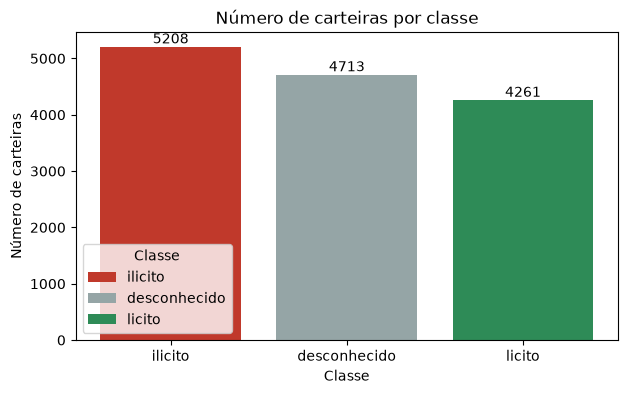

In [29]:
# [IA] Claude Code – código do gráfico 1 (tipo escolhido pelo Vagner: barras das classes)
contagem = nos["classe"].value_counts()[ORDEM]

fig, ax = plt.subplots(figsize=(7, 4))
barras = ax.bar(ORDEM, contagem, color=[CORES[c] for c in ORDEM], label=ORDEM)
ax.bar_label(barras)
ax.set_title("Número de carteiras por classe")
ax.set_xlabel("Classe")
ax.set_ylabel("Número de carteiras")
ax.legend(title="Classe")
plt.savefig(SAIDA + "exploratoria_1.png", dpi=150, bbox_inches="tight")
plt.show()

**Nota analítica do gráfico 1 (Vagner)**

O gráfico mostra que as três classes têm quantidades parecidas de carteiras. A classe ilícita é a maior, com 5.208 carteiras, seguida pela classe desconhecida, com 4.713, e pela lícita, com 4.261. Portanto, nenhuma classe está muito acima das outras. Mesmo assim, é importante lembrar que esses números representam apenas o recorte analisado, e não toda a rede Bitcoin.

Esse gráfico foi escolhido pois dá para ter uma boa visualização de quão próximo são o lícito, ilícito e desconhecido no número de carteiras. Por isso foi iniciado em 0 a contagem na barra.

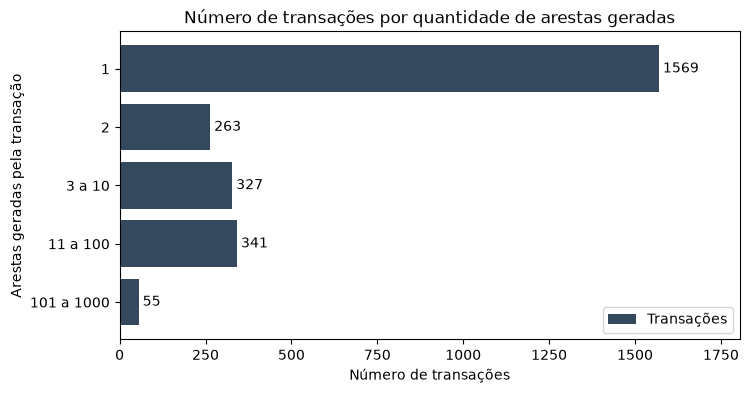

n_arestas
1             1569
2              263
3 a 10         327
11 a 100       341
101 a 1000      55
Total de transações: 2555 | maior número de arestas: 500


In [30]:
# [IA] Claude Code – código do gráfico 2 (tipo e faixas escolhidos pelo Vagner: barras horizontais, transações por faixa de número de arestas)
faixas = pd.cut(transacoes_rec["n_arestas"], bins=[0, 1, 2, 10, 100, 1000],
                labels=["1", "2", "3 a 10", "11 a 100", "101 a 1000"])
tx_por_faixa = faixas.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 4))
barras = ax.barh(tx_por_faixa.index.astype(str), tx_por_faixa.values, color="#34495e", label="Transações")
ax.bar_label(barras, padding=3)
ax.invert_yaxis()
ax.set_xlim(0, tx_por_faixa.max() * 1.15)
ax.set_title("Número de transações por quantidade de arestas geradas")
ax.set_xlabel("Número de transações")
ax.set_ylabel("Arestas geradas pela transação")
ax.legend()
plt.savefig(SAIDA + "exploratoria_2.png", dpi=150, bbox_inches="tight")
plt.show()
print(tx_por_faixa.to_string())
print("Total de transações:", tx_por_faixa.sum(), "| maior número de arestas:", transacoes_rec["n_arestas"].max())


**Nota analítica do gráfico 2 (Vagner)**

O gráfico mostra quantas arestas cada transação gera, em um total de 2.555 transações. Dessas, 1.569 (61,4%) geram apenas uma aresta e 55 (2,2%) geram de 101 a 1.000 arestas. Além disso, 2.159 transações geram de 1 a 10 arestas, o que dá 84,5% do total.

Esse gráfico é importante, pois é possível perceber quantas arestas há em cada transação, e com as barras horizontais dá para ver isso de forma clara.

Vale ressaltar que transações diferentes podem gerar a mesma aresta de uma carteira A para uma carteira B. Nessa situação, essas arestas são contadas de forma individual em cada transação.

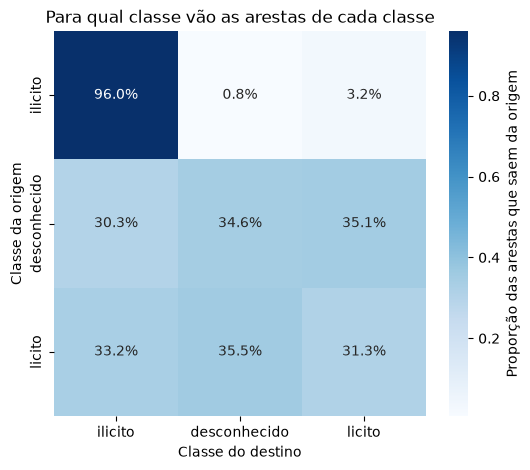

In [31]:
# [IA] Claude Code – código do gráfico 3 (tipo escolhido pelo Vagner: heatmap origem × destino)
tabela = pd.crosstab(arestas["classe_origem"], arestas["classe_destino"], normalize="index")
tabela = tabela.loc[ORDEM, ORDEM]

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(tabela, annot=True, fmt=".1%", cmap="Blues", ax=ax,
            cbar_kws={"label": "Proporção das arestas que saem da origem"})
ax.set_title("Para qual classe vão as arestas de cada classe")
ax.set_xlabel("Classe do destino")
ax.set_ylabel("Classe da origem")
plt.savefig(SAIDA + "exploratoria_3.png", dpi=150, bbox_inches="tight")
plt.show()


**Nota analítica do gráfico 3 (Vagner)**

O gráfico mostra para quais classes vão as arestas que saem de cada tipo de carteira. As carteiras ilícitas se conectam principalmente com outras ilícitas: 96% das suas arestas chegam nessa mesma classe. Já as carteiras desconhecidas e lícitas distribuem suas conexões de forma mais equilibrada entre as três classes, com valores próximos de um terço para cada uma. Isso mostra uma forte concentração das conexões entre carteiras ilícitas.

Esse gráfico foi escolhido pois é de fácil visualização perceber o quanto as outras carteiras vão para distintas carteiras de forma quase que igual entre elas e a carteira ilícita vai praticamente apenas para a carteira ilícita.

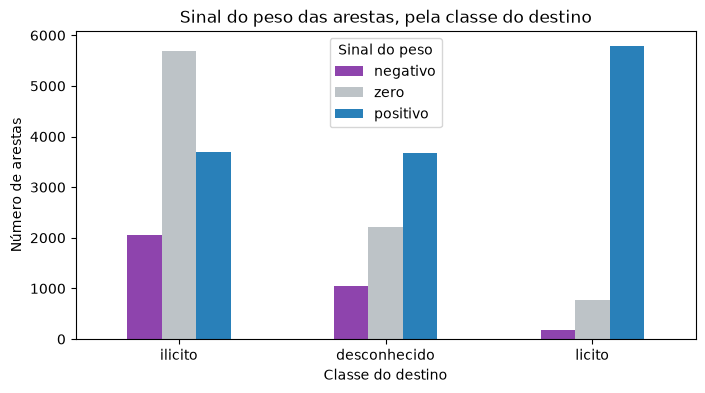

In [32]:
# [IA] Claude Code – código do gráfico 4 (tipo escolhido pelo Vagner: sinal dos pesos por classe do destino)
arestas["sinal_peso"] = np.sign(arestas["peso"]).map({-1: "negativo", 0: "zero", 1: "positivo"})
sinais = pd.crosstab(arestas["classe_destino"], arestas["sinal_peso"])
sinais = sinais.loc[ORDEM, ["negativo", "zero", "positivo"]]

fig, ax = plt.subplots(figsize=(8, 4))
sinais.plot(kind="bar", ax=ax, color=["#8e44ad", "#bdc3c7", "#2980b9"], rot=0)
ax.set_title("Sinal do peso das arestas, pela classe do destino")
ax.set_xlabel("Classe do destino")
ax.set_ylabel("Número de arestas")
ax.legend(title="Sinal do peso")
plt.savefig(SAIDA + "exploratoria_4.png", dpi=150, bbox_inches="tight")
plt.show()

**Nota analítica do gráfico 4 (Vagner)**

O gráfico mostra o sinal do peso das arestas de acordo com a classe da carteira de destino. Nas carteiras ilícitas, predominam os pesos zero, mas também há uma quantidade relevante de pesos positivos e negativos. Nas carteiras desconhecidas, os pesos positivos são maioria, seguidos pelos pesos zero e negativos. Já nas carteiras lícitas, uma grande maioria têm peso positivo, com poucos casos de peso zero ou negativo. Portanto, os pesos positivos aparecem principalmente nas carteiras lícitas, enquanto os pesos negativos são mais comuns nas carteiras ilícitas e desconhecidas.

É importante ressaltar que o peso de uma aresta é o saldo da carteira de destino, ou seja, o total recebido menos o total enviado. Caso uma carteira receba um total de 30 bitcoins de 5 carteiras e envie 50 bitcoins para outra carteira, o saldo dela é −20, e as 5 arestas que chegam nela ficam com peso negativo.

Esse gráfico foi escolhido pois é de fácil visualização em ver o peso de cada aresta dependendo do tipo, pois com as barras agrupadas, dá pra ver sinais entre as classes.

## 8. Gráficos explanatórios (≥ 2)

Falta fazer

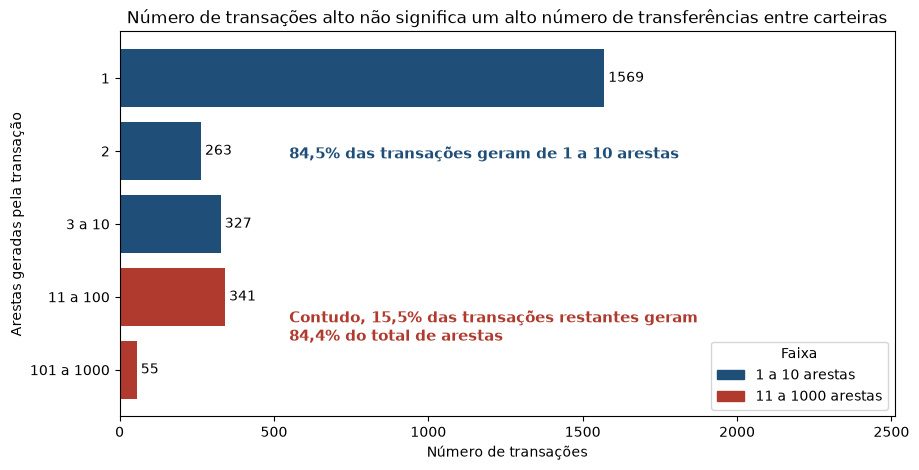

Transações: 1 a 10 = 84.5% | 11 a 1000 = 15.5%
Arestas: 1 a 10 = 3967 (15.6%) | 11 a 1000 = 21520 (84.4%) | total = 25487


In [33]:
# [IA] Claude Code – sintaxe matplotlib do explanatório de arestas por transação; base no gráfico 2, título, cores (azul 1 a 10, vermelho 11 a 1000) e anotações com as porcentagens definidos pelo Vagner
from matplotlib.patches import Patch

grupo_1_10 = ["1", "2", "3 a 10"]
cor_azul, cor_vermelha = "#1f4e79", "#b03a2e"
cores = [cor_azul if f in grupo_1_10 else cor_vermelha for f in tx_por_faixa.index.astype(str)]
arestas_por_faixa = transacoes_rec.groupby(faixas, observed=False)["n_arestas"].sum()
eh_1_10 = tx_por_faixa.index.astype(str).isin(grupo_1_10)
pct_tx_1_10 = 100 * tx_por_faixa[eh_1_10].sum() / tx_por_faixa.sum()
pct_tx_11_1000 = 100 * tx_por_faixa[~eh_1_10].sum() / tx_por_faixa.sum()
pct_arestas_1_10 = 100 * arestas_por_faixa[eh_1_10].sum() / arestas_por_faixa.sum()
pct_arestas_11_1000 = 100 * arestas_por_faixa[~eh_1_10].sum() / arestas_por_faixa.sum()

def pct(v):
    return f"{v:.1f}%".replace(".", ",")

fig, ax = plt.subplots(figsize=(10, 5))
barras = ax.barh(tx_por_faixa.index.astype(str), tx_por_faixa.values, color=cores)
ax.bar_label(barras, padding=3)
ax.invert_yaxis()
ax.set_xlim(0, tx_por_faixa.max() * 1.6)
ax.set_title("Número de transações alto não significa um alto número de transferências entre carteiras")
ax.set_xlabel("Número de transações")
ax.set_ylabel("Arestas geradas pela transação")
ax.text(tx_por_faixa.max() * 0.35, 1.1, f"{pct(pct_tx_1_10)} das transações geram de 1 a 10 arestas",
        fontsize=11, color=cor_azul, fontweight="bold")
ax.text(tx_por_faixa.max() * 0.35, 3.6,
        f"Contudo, {pct(pct_tx_11_1000)} das transações restantes geram\n{pct(pct_arestas_11_1000)} do total de arestas",
        fontsize=11, color=cor_vermelha, fontweight="bold")
ax.legend(handles=[Patch(color=cor_azul, label="1 a 10 arestas"), Patch(color=cor_vermelha, label="11 a 1000 arestas")],
          title="Faixa", loc="lower right")
plt.savefig(SAIDA + "explanatoria_arestas_por_transacao.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Transações: 1 a 10 = {pct_tx_1_10:.1f}% | 11 a 1000 = {pct_tx_11_1000:.1f}%")
print(f"Arestas: 1 a 10 = {arestas_por_faixa[eh_1_10].sum()} ({pct_arestas_1_10:.1f}%) | 11 a 1000 = {arestas_por_faixa[~eh_1_10].sum()} ({pct_arestas_11_1000:.1f}%) | total = {arestas_por_faixa.sum()}")


**Nota analítica do explanatório de arestas por transação (Vagner)**

O gráfico mostra que 84,5% das transações geram de 1 a 10 arestas. Contudo, os 15,5% restantes, que geram de 11 a 1000 arestas, respondem por 84,4% do total de arestas (21.520 de 25.487).

Dá para perceber pelo gráfico duas coisas. Primeiro, a grande maioria das transações ocorre com poucas arestas saindo dela. Segundo, as transações com maior número de arestas, mesmo sendo poucas, somam a maior parte do total de arestas.

Lembrando que uma aresta é a ligação de uma carteira para outra carteira, e uma transação é composta por várias dessas ligações.

Esse gráfico foi escolhido em barras horizontais, pois é uma forma de utlizar barras no eixo x,y, também foi considerado útil por no eixo x,y esse gráfico, e as partes principais foram coloridas de azul e vermelho para mostrar a discrepância entre elas. O título foi usado para mostrar que um número alto de transações não quer dizer um alto número de transferências. Ao lado das barras, com a mesma cor delas, foi posta a frase que explica o que cada grupo representa.


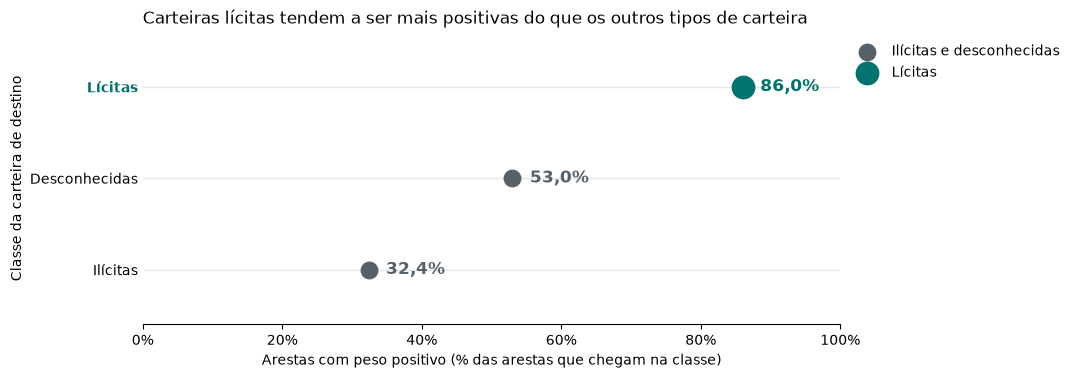

                positivo  total  % positivo
classe_destino                             
ilicito             3703  11439        32.4
desconhecido        3677   6937        53.0
licito              5794   6735        86.0


In [34]:
# [IA] Claude Code – sintaxe matplotlib do explanatório 2 (dot plot); tipo de gráfico, ideia, título e destaque das lícitas definidos pelo Vagner, com base no gráfico 4
pct_positivo = (100 * sinais["positivo"] / sinais.sum(axis=1)).loc[["ilicito", "desconhecido", "licito"]]
nomes = {"licito": "Lícitas", "desconhecido": "Desconhecidas", "ilicito": "Ilícitas"}
cor_destaque, cor_demais = "#00736f", "#56616a"

fig, ax = plt.subplots(figsize=(9, 3.8))
for y, (classe, valor) in enumerate(pct_positivo.items()):
    cor = cor_destaque if classe == "licito" else cor_demais
    tamanho = 260 if classe == "licito" else 140
    ax.hlines(y, 0, 100, color="#e3e7ea", linewidth=1, zorder=1)
    ax.scatter(valor, y, s=tamanho, color=cor, zorder=3)
    ax.text(valor + 2.5, y, f"{valor:.1f}%".replace(".", ","), va="center", fontsize=12, fontweight="bold", color=cor)
ax.set_yticks(range(len(pct_positivo)), [nomes[c] for c in pct_positivo.index])
ax.get_yticklabels()[-1].set_color(cor_destaque)
ax.get_yticklabels()[-1].set_fontweight("bold")
ax.set_xlim(0, 100)
ax.set_ylim(-0.6, len(pct_positivo) - 0.4)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0f}%"))
for lado in ["top", "right", "left"]:
    ax.spines[lado].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.set_title("Carteiras lícitas tendem a ser mais positivas do que os outros tipos de carteira", loc="left")
ax.set_xlabel("Arestas com peso positivo (% das arestas que chegam na classe)")
ax.set_ylabel("Classe da carteira de destino")
ax.scatter([], [], s=140, color=cor_demais, label="Ilícitas e desconhecidas")
ax.scatter([], [], s=260, color=cor_destaque, label="Lícitas")
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), frameon=False)
plt.savefig(SAIDA + "explanatoria_2.png", dpi=150, bbox_inches="tight")
plt.show()
print(pd.DataFrame({"positivo": sinais["positivo"], "total": sinais.sum(axis=1), "% positivo": (100 * sinais["positivo"] / sinais.sum(axis=1)).round(1)}))


**Nota analítica do explanatório 2 (Vagner)**

Escolhi o dot plot porque ele é uma boa forma de apresentar que as carteiras lícitas tendem a ser mais positivas do que as outras. Deixei a bola das lícitas pintada de verde, diferente das outras, para destacar essa classe e deixar claro qual é ela.

Falta deixar mais explicado a mudança.

## 9. Da exploração à explicação

Falta fazer